# 04 · Benign Overfitting

**Claim:** zero training error is not doom. A model can memorise every noisy training label, reproducing the noise exactly, and still predict new points better than the carefully sized classical model.

*Double Descent 101 · notebook 4 of 6 · previous: [03 · The second descent](03_the_second_descent.ipynb) · next: [05 · More data can hurt](05_more_data_can_hurt.ipynb)*

## The setting

The 20-D random-feature track: $n = 100$ noisy points, target $f(x) = \tanh(2\langle\beta, x\rangle)$, min-norm least squares on $p$ random ReLU features. Three models from the same family:

| Model | $p$ | Training error | Role |
|---|---|---|---|
| Classical sweet spot | best $p < n$ | > 0 | what the bias-variance tradeoff recommends |
| Threshold | $p = n$ | 0 | the worst possible size (notebook 02) |
| Interpolating | $p = 20n = 2000$ | 0 | memorises every label |

Plus the **null predictor** (always predict 0), whose test error is the signal variance of about 0.64.

In [1]:
import numpy as np
import pandas as pd

from src.config import get_settings
from src.evaluation import aggregate, example_fits, factory_for, run_capacity_experiment, summarize_curve, task_for
from src.reporting import publish_figure, save_json
from src.theory.decomposition import signal_noise_split
from src.visualisation import (
    INK, INK_2, MODEL_COLORS, MUTED, SERIES, SURFACE, VARIANCE_COLOR, BIAS_COLOR,
    capacity_axes, format_error, new_figure, plot_band,
)

settings = get_settings()
SIGMA = settings.headline_noise
M = "random_features"
N = settings.random_features.n_train
task = task_for(M, settings)
NULL_MSE = task.signal_variance()

sweep = run_capacity_experiment(M, settings)
test = aggregate(sweep)
summ = {s: summarize_curve(test[test["noise"] == s], N) for s in settings.noise_levels}
P_SWEET = summ[SIGMA].classical_min_params
P_BIG = summ[SIGMA].final_params
print(f"null predictor MSE = {NULL_MSE:.3f}; sweet spot p = {P_SWEET}; interpolating p = {P_BIG}")

null predictor MSE = 0.643; sweet spot p = 32; interpolating p = 2000


## Memorise the training set, predict the test set

One training draw. Left: predictions on the **training** points against their noisy labels. Middle and right: predictions on 2,000 fresh **test** points. The target depends on $x$ only through $t = \langle\beta, x\rangle$, so plotting against $t$ shows the true function as one curve.

{'png': '/workspaces/double_descent_101/outputs/figures/04_memorize_and_generalize.png',
 'json': '/workspaces/double_descent_101/outputs/data/04_memorize_and_generalize.json'}

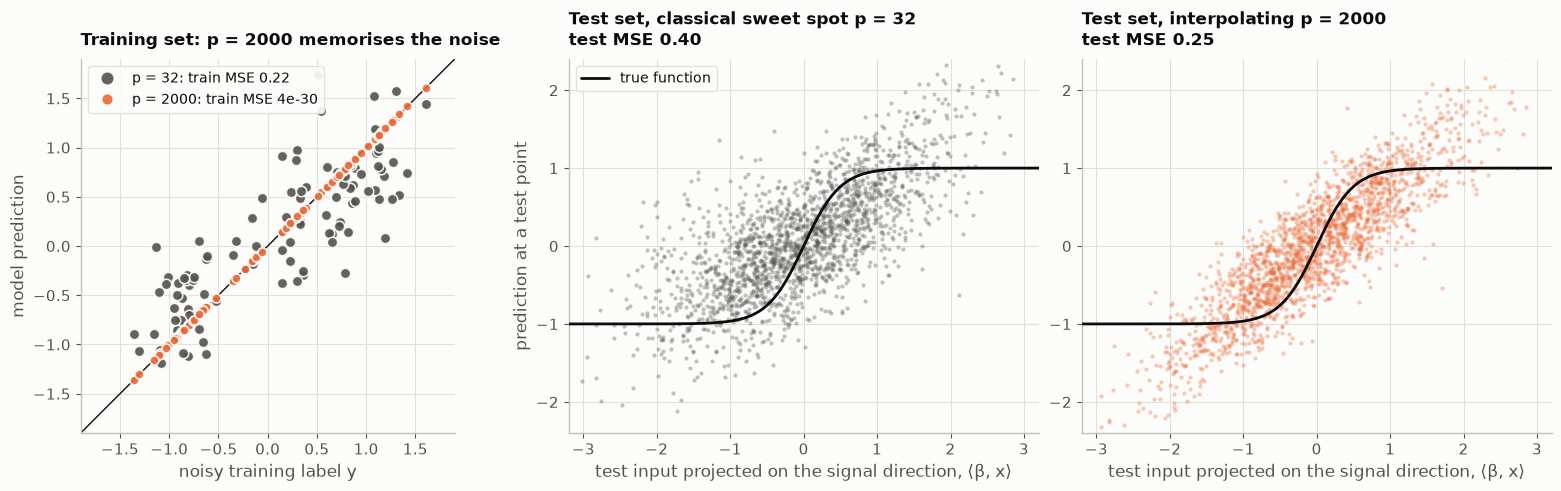

In [2]:
ex = example_fits(settings, [P_SWEET, P_BIG], noise=SIGMA, model=M)
from src.datasets.synthetic import ridge_direction
proj = ex.x_grid @ ridge_direction(task.dim, task.truth_seed)
order = np.argsort(proj)
styles = {P_SWEET: ("#52514e", f"classical sweet spot, p = {P_SWEET}"), P_BIG: (MODEL_COLORS[M], f"interpolating, p = {P_BIG}")}
fig, axes = new_figure(ncols=3, width=15.5, height=4.8)
lims = (-1.9, 1.9)
axes[0].plot(lims, lims, color=INK, lw=1.0, zorder=1)
axes[0].set_xlim(*lims); axes[0].set_ylim(*lims); axes[0].set_aspect("equal")
for p, (col, lab) in styles.items():
    mse = f"{ex.train_mse[p]:.0e}" if ex.train_mse[p] < 1e-6 else f"{ex.train_mse[p]:.2f}"
    axes[0].plot(ex.y_train, ex.train_predictions[p], "o", ms=6.5 if p == P_BIG else 7.5, color=col,
                 mec=SURFACE, mew=1.2, alpha=0.9, label=f"p = {p}: train MSE {mse}")
axes[0].set_xlabel("noisy training label y")
axes[0].set_ylabel("model prediction")
axes[0].set_title("Training set: p = 2000 memorises the noise", fontsize=12.5)
axes[0].legend(loc="upper left", fontsize=10, markerscale=1.3)
for ax, (p, (col, lab)) in zip(axes[1:], styles.items()):
    ax.plot(proj, ex.predictions[p], "o", ms=3.0, color=col, alpha=0.35, mew=0, zorder=2)
    ax.plot(proj[order], ex.f_grid[order], color=INK, lw=2.0, label="true function", zorder=3)
    ax.set_xlim(-3.2, 3.2); ax.set_ylim(-2.4, 2.4)
    ax.set_xlabel("test input projected on the signal direction, ⟨β, x⟩")
    ax.set_title(f"Test set, {lab.split(',')[0]} p = {p}\ntest MSE {format_error(ex.test_mse[p])}", fontsize=12.5)
axes[1].set_ylabel("prediction at a test point")
axes[1].legend(loc="upper left", fontsize=10)
publish_figure(
    fig, "04_memorize_and_generalize", "Memorise and still generalise",
    f"One training draw of the 20-D random-feature track (n = {N}, σ = {SIGMA}). Left: predictions on the training "
    f"points vs their noisy labels. Middle and right: predictions on 2,000 test points against their projection on "
    f"the signal direction, with the true function. The p = {P_BIG} model reproduces every training label exactly "
    "and its test predictions hug the truth more tightly.",
    {"noise": SIGMA, "n_train": N,
     "train": {"y": ex.y_train, **{f"pred_p{p}": ex.train_predictions[p] for p in styles}},
     "test_subsample": {"projection": proj[::4], "f": ex.f_grid[::4], **{f"pred_p{p}": ex.predictions[p][::4] for p in styles}},
     "train_mse": ex.train_mse, "test_mse": ex.test_mse},
)

The left panel is what every course warns about: the interpolating model's predictions sit exactly on the diagonal. It has reproduced every noisy label, noise included. The other two panels are what the warning gets wrong: on new points, the same model scatters more tightly around the truth than the classical model that refused to fit the noise.

## Where did the memorised noise go?

Least squares is linear in the labels. Split $y = f + \sigma\varepsilon$ and the fit splits the same way, $\hat\theta = \hat\theta_{\text{signal}} + \hat\theta_{\text{noise}}$: one part fitted to the clean signal, one part fitted to pure noise. Past the threshold, $\hat\theta_{\text{noise}}$ reproduces the noise **exactly** on the training points. Benign overfitting is the claim that its footprint on **test** points, $\mathbb{E}\,(\phi(x)^\top\hat\theta_{\text{noise}})^2$, is small.

noise footprint: p=n 27.05 -> p=2000 0.064  (noise variance σ² = 0.09)


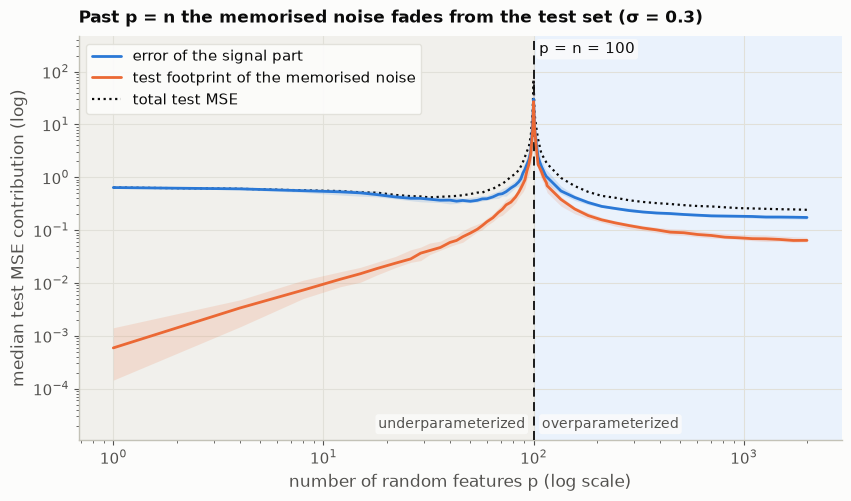

In [3]:
grid = sorted(test["n_params"].unique())
split = signal_noise_split(factory_for(M, settings), task, n_train=N, noise=SIGMA, n_params_grid=grid,
                           n_seeds=settings.random_features.n_seeds, seed=settings.seed)
over = split[split["n_params"] >= N]
assert (over["train_mse"] < 1e-15).all()  # memorised exactly
med = split.groupby("n_params").agg(["median", lambda s: s.quantile(0.25), lambda s: s.quantile(0.75)])

fig, (ax,) = new_figure(width=8.4, height=4.9)
x = med.index.to_numpy(dtype=float)
for col_name, color, label in [("signal_error", BIAS_COLOR, "error of the signal part"),
                               ("noise_energy", VARIANCE_COLOR, "test footprint of the memorised noise")]:
    m = med[col_name]
    plot_band(ax, x, m.iloc[:, 0].to_numpy(), m.iloc[:, 1].to_numpy(), m.iloc[:, 2].to_numpy(), color, label)
ax.plot(x, med["total"].iloc[:, 0], color=INK, lw=1.6, ls=(0, (1, 1.6)), label="total test MSE")
capacity_axes(ax, N, xlabel="number of random features p (log scale)", ylabel="median test MSE contribution (log)", logx=True)
ax.set_title(f"Past p = n the memorised noise fades from the test set (σ = {SIGMA})", fontsize=12.5)
ax.legend(loc="upper left", fontsize=10.5)
publish_figure(
    fig, "04_signal_noise_split", "Where the memorised noise goes",
    f"Min-norm fit split into the part fitted to the clean signal and the part fitted to the noise (random-feature "
    f"track, n = {N}, σ = {SIGMA}). For every p ≥ n the noise part reproduces the training noise exactly, yet its "
    "effect on test points shrinks steadily as p grows. Median and IQR over training draws.",
    {"noise": SIGMA, "n_train": N, "n_params": x,
     "signal_error_median": med["signal_error"].iloc[:, 0].to_numpy(),
     "noise_energy_median": med["noise_energy"].iloc[:, 0].to_numpy(),
     "total_median": med["total"].iloc[:, 0].to_numpy()},
)
ne = med["noise_energy"].iloc[:, 0]
print(f"noise footprint: p=n {ne.loc[N]:.2f} -> p={P_BIG} {ne.loc[P_BIG]:.3f}  (noise variance σ² = {SIGMA**2:.2f})")

At $p = n$ the memorised noise alone adds about 27 to the median test error, three hundred times the noise variance of 0.09. By $p = 2000$ its footprint is down to about 0.06, *smaller than the noise variance itself*, even though every noisy label is still reproduced exactly. Past the threshold, each extra random feature gives the min-norm solution another direction in which to stash noise. With 2,000 features in 20-D there are plenty of directions that barely matter for predictions at new points, so the noise is spread thin across them. That is the intuition behind benign overfitting (Bartlett et al., 2020): the noise is fitted, but in directions that do not hurt.

The signal part follows the same shape. Its error also spikes at $p = n$ and also descends afterwards, ending below its classical-regime minimum. The part of $f$ that a finite set of random features cannot represent behaves like noise to the fit. Both parts gain from the extra room past the threshold.

## The scoreboard, at every noise level

,null predictor,classical sweet spot,threshold p = n,interpolating p = 2000,sweet spot p
noise,,,,,
0.0,0.643,0.352,30.270,0.174,50
0.1,0.643,0.369,34.050,0.181,43
0.3,0.643,0.417,71.448,0.243,32
0.5,0.643,0.495,81.495,0.363,22


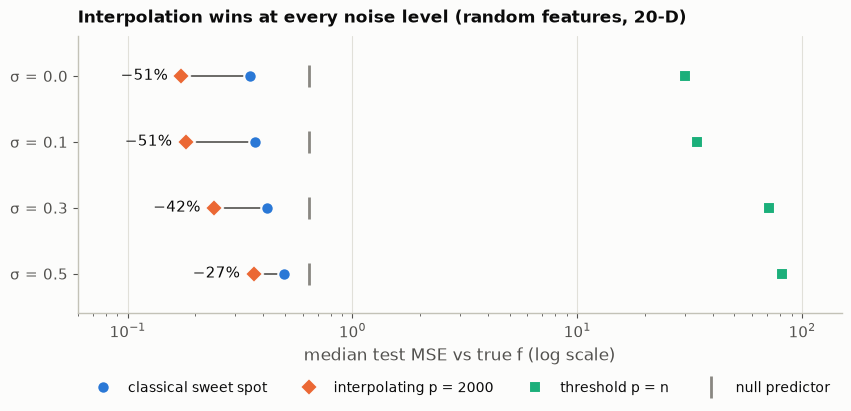

In [4]:
rows = []
for s in settings.noise_levels:
    c = test[test["noise"] == s].set_index("n_params")["median"]
    rows.append({"noise": s, "null predictor": NULL_MSE, "classical sweet spot": summ[s].classical_min_error,
                 "threshold p = n": c.loc[N], f"interpolating p = {P_BIG}": c.loc[P_BIG],
                 "sweet spot p": summ[s].classical_min_params})
board = pd.DataFrame(rows).set_index("noise")

marks = [("classical sweet spot", SERIES[0], "o"), (f"interpolating p = {P_BIG}", SERIES[1], "D"),
         ("threshold p = n", SERIES[2], "s"), ("null predictor", MUTED, "|")]
fig, (ax,) = new_figure(width=8.4, height=4.0)
ys = np.arange(len(board))
for label, color, marker in marks:
    ax.plot(board[label], ys, marker, ms=9 if marker != "|" else 16, mew=2 if marker == "|" else 1.5,
            color=color, mec=SURFACE if marker != "|" else color, label=label, ls="none", zorder=4)
for y, (_, r) in zip(ys, board.iterrows()):
    big, sweet = r[f"interpolating p = {P_BIG}"], r["classical sweet spot"]
    ax.plot([big, sweet], [y, y], color=INK_2, lw=1.2, zorder=3)
    ax.annotate(f"−{1 - big / sweet:.0%}", xy=(big, y), xytext=(-10, 0), textcoords="offset points",
                ha="right", va="center", fontsize=10.5, color=INK)
ax.set_xscale("log")
ax.set_xlim(0.06, 150)
ax.set_yticks(ys, [f"σ = {s}" for s in board.index])
ax.set_ylim(-0.6, len(board) - 0.4)
ax.invert_yaxis()
ax.set_xlabel("median test MSE vs true f (log scale)")
ax.set_title("Interpolation wins at every noise level (random features, 20-D)", fontsize=12.5)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=4, fontsize=10, frameon=False)
ax.grid(axis="y", visible=False)
publish_figure(
    fig, "04_scoreboard", "The scoreboard",
    f"Median test error of the best classical model (p < n), the threshold model (p = n), the interpolating model "
    f"(p = {P_BIG}) and the always-zero predictor, at four noise levels (random-feature track, n = {N}).",
    {"n_train": N, "table": board.reset_index()},
)
board.round(3)

## What you just saw

- **Zero training error, better test error.** The interpolating random-feature model reproduces every noisy label and still beats the classical sweet spot at every noise level tried, with between about 25% and 50% lower test error (the gap narrows as noise grows).
- **The noise is fitted, but where it does no harm.** By linearity the fit splits into a signal part and a noise part. The noise part is exact on the training points, yet at $p = 2000$ its effect on test points is smaller than the noise variance itself.
- **Benign is not automatic.** In 1-D polynomials (notebook 03) the same interpolation only came close to the sweet spot. It needs room: many directions that matter little for prediction, which is what high dimensions and wide feature maps provide. Zero training error tells you nothing on its own. Capacity, dimension, and which interpolant you get decide the outcome.

Next, notebook 05 shows the same threshold from the other side: hold the model fixed and add data.

In [5]:
save_json(
    {
        "notebook": "04_benign_overfitting",
        "claim": "A model with zero training error on noisy labels can generalise better than the classical sweet spot.",
        "settings": {"headline_noise": SIGMA, "n_train": N, "dim": settings.random_features.task.dim,
                     "interpolating_n_params": P_BIG, "seed": settings.seed},
        "results": {
            "example_draw": {"train_mse": ex.train_mse, "test_mse": ex.test_mse},
            "noise_footprint_median": {"at_threshold": float(ne.loc[N]), "at_interpolating": float(ne.loc[P_BIG])},
            "null_predictor_mse": NULL_MSE,
            "scoreboard": board.reset_index(),
        },
        "figures": ["04_memorize_and_generalize", "04_signal_noise_split", "04_scoreboard"],
        "takeaways": [
            "The interpolating model memorises every noisy label yet has lower test error than the classical sweet spot.",
            "Split by linearity, the memorised-noise part of the fit has a test footprint that shrinks as capacity grows.",
            "Benign overfitting needs room (high dimension, wide feature maps); in 1-D it only comes close.",
        ],
        "next": "05_more_data_can_hurt",
    },
    "04_summary",
)

PosixPath('/workspaces/double_descent_101/outputs/data/04_summary.json')